# 07. Cascade Spread Prediction & Virality Regression

- **Role/Owner:** Member 3 (Analytics, Graph & Visualization Lead)
- **Core Responsibility:** Train Ridge Regression models that estimate how many **unique users** a rumour cascade will reach (FR2), from the author's followers and verified badge and, once the post has been live for 15 minutes, from its **engagement velocity**, and turn the estimate into a Low / Moderate / High spread risk.
- **Key Interface/Contract:** Consumes `backend/data/processed/cascade_features.csv` (splits) and `backend/data/processed/pheme_interactions.csv.gz` (one row per tweet, built by `backend/scripts/extract_pheme_interactions.py`); outputs `backend/models/spread_regressor.joblib` (read by `app/services/cascade.py`) and `backend/reports/spread_metrics.json`.

**Where the user and time data come from.** The graph file used in notebooks 01 and 02 (`pheme_political/pheme_cascades.gpickle`, from Hugging Face) has no user ids and no timestamps. The raw PHEME veracity release (figshare 6392078, CC BY 4.0) has both for every tweet. `extract_pheme_interactions.py` keeps only what this notebook and notebook 06 need, replaces the real user ids with keys such as `u123`, and drops the tweet text, so the table can live in the public repo.

**Two modes, two models.**

| Mode | When | Model | Target |
|---|---|---|---|
| **Live post** | the post has been online for 15 minutes | velocity model: followers, verified, replies in the first 15 minutes | `new_users_after_15m`: users who join **after** minute 15 |
| **New claim** | the claim has not been posted yet, nothing observed | author-only model: followers, verified | `unique_users`: all users in the finished cascade |

For a live post the reach shown to the user is `observed_users_15m + predicted new_users_after_15m`: the users already seen are counted, not predicted.

**Correction to an earlier version.** An earlier version of this notebook predicted the total `unique_users` from the replies in the first 30 minutes. The users who replied in those 30 minutes are part of the total, so the model was partly counting what it had already seen, and its test R2 of 0.629 was inflated. This version predicts only the part after the cutoff and scores only that part.

**What this notebook does**

1. Load the 6,425 PHEME cascades with the same `split` column as the text models.
2. Build the targets (users after the cutoff, total users) and the velocity feature.
3. Check which columns are allowed.
4. Train the velocity model and the author-only model, each against a "predict the average" baseline; tune `alpha` on validation and report the test set once.
5. Compare cutoffs of 5, 15, 30 and 60 minutes, test on events the model has never seen, and turn the estimates into risk levels.

## 1. Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SEED = 42
WINDOW = 15                         # cutoff in minutes after the source tweet (team decision)
WINDOWS = [5, 15, 30, 60]           # compared in Section 6
ALPHAS = np.logspace(-2, 4, 13)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").exists())
DATA = ROOT / "backend" / "data" / "processed"
MODELS = ROOT / "backend" / "models"
REPORTS = ROOT / "backend" / "reports"
MODELS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: /Users/phaman/Documents/COS30048 - Inno/inno


## 2. Load the cascades, the tweets and the splits

`cascade_features.csv` has one row per cascade and the `split` column: `train`, `val`, `test`, `excluded_label` and `excluded_dup`.

- `train / val / test` are the cascades whose source tweet is in the text-model splits. We use these.
- `excluded_label` are cascades dropped by the label rules (unverified rumours and two almost-all-false events). Spread prediction does not need the true/false label, so we test adding them as **Experiment B**, but keep them out of the main models so the comparison with the other notebooks stays fair.
- `excluded_dup` are cascades whose source text was a duplicate. We never use them, because a duplicate could appear in both train and test.

`pheme_interactions.csv.gz` has one row per tweet: thread, pseudonymous user key, the user it replies to, minutes after the source tweet, followers and verified flag.

In [2]:
df = pd.read_csv(DATA / "cascade_features.csv", dtype={"cascade_id": str})
tweets = pd.read_csv(DATA / "pheme_interactions.csv.gz", dtype={"thread_id": str})
assert len(df) == 6425, f"expected 6,425 cascades, found {len(df):,}"
assert tweets["thread_id"].nunique() == 6425 and set(tweets["thread_id"]) == set(df["cascade_id"])
print(f"{len(tweets):,} tweets from {tweets['user_key'].nunique():,} users")
print(df["split"].value_counts().to_string())

104,582 tweets from 50,593 users
split
train             3757
excluded_label     937
test               805
val                805
excluded_dup       121


## 3. Targets and features

For every cascade and every cutoff W (5, 15, 30, 60 minutes):

- **`unique_users`**: the number of different accounts in the finished cascade (author plus everyone who replied). FR2 asks for "expected audience reach (unique user count)".
- **`observed_users_<W>m`**: different accounts already seen by minute W, **including the author** (the source tweet is at minute 0).
- **`new_users_after_<W>m`**: accounts whose **first** tweet in the cascade comes after minute W. By construction `unique_users = observed_users_<W>m + new_users_after_<W>m`.
- **`replies_<W>m`**: replies posted by minute W. This is the engagement velocity in FR2.
- **Author**: followers and verified flag of the source tweet's author, from the source tweet itself (the follower count at posting time).

In [3]:
source = tweets[tweets["is_source"] == 1].set_index("thread_id")
replies = tweets[tweets["is_source"] == 0]
first_seen = tweets.groupby(["thread_id", "user_key"])["minutes_after_source"].min().reset_index()

per = pd.DataFrame({
    "unique_users": first_seen.groupby("thread_id").size(),
    "author_followers": source["user_followers"],
    "author_verified": source["user_verified"],
})
for w in WINDOWS:
    per[f"replies_{w}m"] = (replies[replies["minutes_after_source"] <= w]
                            .groupby("thread_id").size().reindex(per.index, fill_value=0))
    per[f"observed_users_{w}m"] = (first_seen[first_seen["minutes_after_source"] <= w]
                                   .groupby("thread_id").size().reindex(per.index, fill_value=0))
    per[f"new_users_after_{w}m"] = per["unique_users"] - per[f"observed_users_{w}m"]

df = df.merge(per, left_on="cascade_id", right_index=True, how="left", validate="one_to_one")
assert df[per.columns].notna().all().all()
assert (df[[f"observed_users_{w}m" for w in WINDOWS]] >= 1).all().all(), "the author is always observed"
assert (df[[f"new_users_after_{w}m" for w in WINDOWS]] >= 0).all().all()

follow_match = (df["author_followers"] == df["root_user_followers"]).mean()
print(f"author followers equal to the graph file's value in {follow_match:.1%} of cascades "
      "(the rest differ because the graph file stored another snapshot of the account)")
cols = ["unique_users", f"observed_users_{WINDOW}m", f"new_users_after_{WINDOW}m", f"replies_{WINDOW}m"]
print(df[cols].describe(percentiles=[.5, .9, .99]).round(1).to_string())

author followers equal to the graph file's value in 88.0% of cascades (the rest differ because the graph file stored another snapshot of the account)
       unique_users  observed_users_15m  new_users_after_15m  replies_15m
count        6425.0              6425.0               6425.0       6425.0
mean           10.8                 5.6                  5.1          5.4
std             7.7                 4.9                  5.5          6.1
min             1.0                 1.0                  0.0          0.0
50%            10.0                 4.0                  4.0          3.0
90%            20.0                13.0                 12.0         14.0
99%            33.0                20.0                 23.0         22.8
max           125.0                65.0                 76.0         97.0


### How much of the reach is already visible at the cutoff?

If most users have already arrived by the cutoff, the visible part explains most of the total, and any model that uses it will look good on the total for that reason alone. This is why the velocity model is trained and scored on the part after the cutoff only.

 cutoff_min  share_of_users_already_seen  cascades_with_no_new_users  median_new_users_after
          5                        0.310                       0.109                     7.0
         15                        0.517                       0.163                     4.0
         30                        0.641                       0.231                     2.0
         60                        0.749                       0.338                     1.0


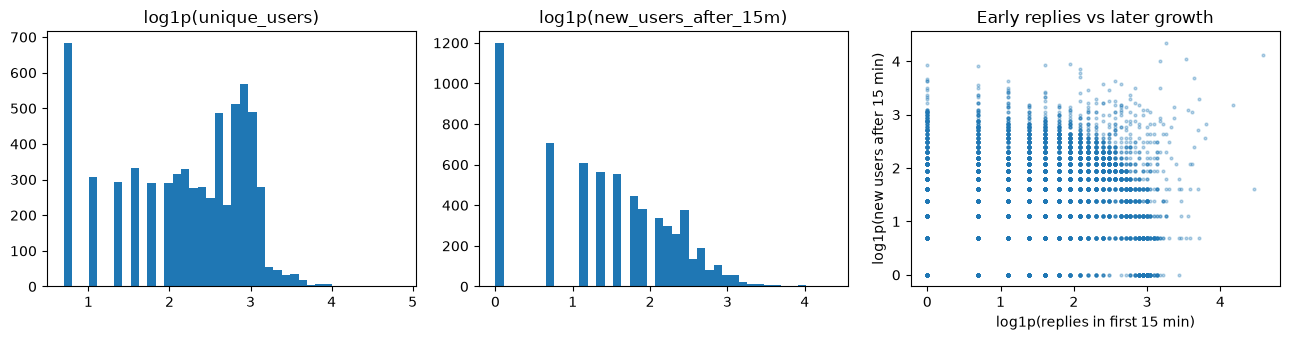

In [4]:
USED = ["train", "val", "test"]
pool = df[df["split"].isin(USED)]
visible = pd.DataFrame([{
    "cutoff_min": w,
    "share_of_users_already_seen": float(pool[f"observed_users_{w}m"].sum() / pool["unique_users"].sum()),
    "cascades_with_no_new_users": float((pool[f"new_users_after_{w}m"] == 0).mean()),
    "median_new_users_after": float(pool[f"new_users_after_{w}m"].median()),
} for w in WINDOWS]).round(3)
print(visible.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(np.log1p(df["unique_users"]), bins=40); ax[0].set_title("log1p(unique_users)")
ax[1].hist(np.log1p(df[f"new_users_after_{WINDOW}m"]), bins=40); ax[1].set_title(f"log1p(new_users_after_{WINDOW}m)")
ax[2].scatter(np.log1p(df[f"replies_{WINDOW}m"]), np.log1p(df[f"new_users_after_{WINDOW}m"]), s=4, alpha=0.3)
ax[2].set_xlabel(f"log1p(replies in first {WINDOW} min)"); ax[2].set_ylabel(f"log1p(new users after {WINDOW} min)")
ax[2].set_title("Early replies vs later growth")
plt.tight_layout(); plt.show()

## 4. Which columns are allowed

| Column | Use | Reason |
|---|---|---|
| `author_followers` | feature (log), both models | known before the cascade starts |
| `author_verified` | feature, both models | known before the cascade starts |
| `replies_15m` | feature (log), velocity model only | known 15 minutes after posting |
| `observed_users_15m` | **added** to the prediction, never a feature | already observed, so it is counted, not predicted |
| `max_depth`, `reply_count`, `n_unique_verified`, `cascade_size` | **not used** | measured from the finished cascade, so they leak the target |
| `label`, `veracity` | not used | not known for a new claim |
| `event` | not used for training | used only to test on unseen events |

Spearman correlations with each target (train, validation and test cascades):

In [5]:
candidates = ["author_followers", "author_verified"] + [f"replies_{w}m" for w in WINDOWS] + \
             ["max_depth", "reply_count", "n_unique_verified", "cascade_size"]
corr = pd.DataFrame({
    "vs unique_users": pool[["unique_users"] + candidates].corr(method="spearman")["unique_users"].drop("unique_users"),
    f"vs new_users_after_{WINDOW}m": pool[[f"new_users_after_{WINDOW}m"] + candidates]
        .corr(method="spearman")[f"new_users_after_{WINDOW}m"].drop(f"new_users_after_{WINDOW}m"),
}).round(3)
corr

,vs unique_users,vs new_users_after_15m
author_followers,0.243,-0.014
author_verified,0.173,-0.025
replies_5m,0.618,0.113
replies_15m,0.733,0.210
replies_30m,0.784,0.329
replies_60m,0.820,0.434
max_depth,0.650,0.567
reply_count,0.928,0.657
n_unique_verified,0.252,0.041
cascade_size,0.900,0.696


## 5. Models, metrics and baselines

Each model is a scikit-learn pipeline: log-transform and standardise the counts, pass the verified flag through, then Ridge regression. Each target is trained on the log scale (`log1p`) and converted back with `expm1`.

Metrics (validation or test only, never training data), always next to a baseline that predicts the training average of the same target:

- **R2 (log scale)**: share of variance explained. 0 means "no better than the average".
- **MAE (users)**: average error in real user counts.
- **Spearman**: does the model rank big cascades above small ones?

**What is scored.** The velocity model is scored on `new_users_after_15m` only. Its total reach is `observed_users_15m + prediction`, and the observed part is exact, so **the MAE on the total equals the MAE on the part after the cutoff** (checked in the next cell). The R2 on the total is not reported: the observed part, which the model does not predict, would make it look high. The author-only model has nothing observed, so it is scored on `unique_users`.

`alpha` is picked on the validation set from 13 values between 0.01 and 10,000.

train            3757 cascades | median unique users 10 | median new users after 15 min 4
val               805 cascades | median unique users 10 | median new users after 15 min 4
test              805 cascades | median unique users 10 | median new users after 15 min 4
excluded_label    937 cascades | median unique users 7 | median new users after 15 min 2


alpha velocity: 0.01 | alpha author-only: 100.0


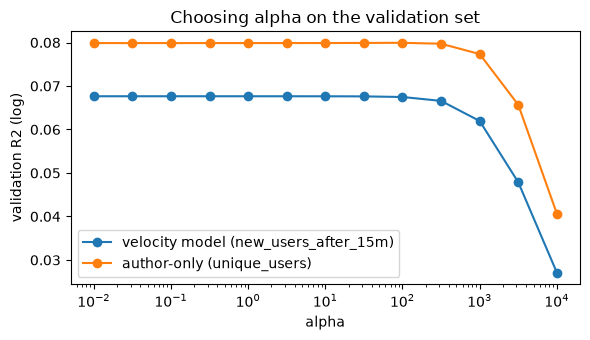

In [6]:
AUTHOR = ["author_followers", "author_verified"]
VELOCITY = AUTHOR + [f"replies_{WINDOW}m"]
NEW = f"new_users_after_{WINDOW}m"
OBS = f"observed_users_{WINDOW}m"
TOTAL = "unique_users"

train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()
extra = df[df["split"] == "excluded_label"].copy()     # only for Experiment B
for name, d in [("train", train), ("val", val), ("test", test), ("excluded_label", extra)]:
    print(f"{name:15s} {len(d):5d} cascades | median unique users {d[TOTAL].median():.0f} | "
          f"median new users after {WINDOW} min {d[NEW].median():.0f}")


def make_pipeline(features, alpha):
    counts = [f for f in features if f != "author_verified"]
    steps = [("counts", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), counts)]
    if "author_verified" in features:
        steps.append(("verified", "passthrough", ["author_verified"]))
    return Pipeline([("prep", ColumnTransformer(steps)), ("ridge", Ridge(alpha=alpha))])


def rank_corr(a, b):
    return float("nan") if np.ptp(b) < 1e-9 else float(spearmanr(a, b)[0])


def evaluate(model, d, features, target):
    y_log, p_log = np.log1p(d[target].to_numpy()), model.predict(d[features])
    p = np.expm1(p_log)
    return {
        "r2_log": float(r2_score(y_log, p_log)),
        "mae_users": float(mean_absolute_error(d[target], p)),
        "rmse_users": float(np.sqrt(mean_squared_error(d[target], p))),
        "spearman": rank_corr(d[target], p_log),
    }


def tune(features, target, fit_rows, val_rows):
    """Pick alpha on val_rows, then return the model refitted on fit_rows with that alpha."""
    y = np.log1p(fit_rows[target])
    scores = [evaluate(make_pipeline(features, a).fit(fit_rows[features], y), val_rows, features, target)["r2_log"]
              for a in ALPHAS]
    best = float(ALPHAS[int(np.argmax(scores))])
    return make_pipeline(features, best).fit(fit_rows[features], y), best, scores


def mean_baseline(target, fit_rows):
    return DummyRegressor(strategy="mean").fit(fit_rows[AUTHOR], np.log1p(fit_rows[target]))


velocity_model, alpha_velocity, scores_velocity = tune(VELOCITY, NEW, train, val)
author_model, alpha_author, scores_author = tune(AUTHOR, TOTAL, train, val)
baseline_new, baseline_total = mean_baseline(NEW, train), mean_baseline(TOTAL, train)
print("alpha velocity:", alpha_velocity, "| alpha author-only:", alpha_author)

plt.figure(figsize=(6, 3.5))
plt.semilogx(ALPHAS, scores_velocity, marker="o", label=f"velocity model ({NEW})")
plt.semilogx(ALPHAS, scores_author, marker="o", label=f"author-only ({TOTAL})")
plt.xlabel("alpha"); plt.ylabel("validation R2 (log)"); plt.legend()
plt.title("Choosing alpha on the validation set")
plt.tight_layout(); plt.show()

In [7]:
results = pd.DataFrame({
    f"velocity: baseline val": evaluate(baseline_new, val, AUTHOR, NEW),
    f"velocity: model val": evaluate(velocity_model, val, VELOCITY, NEW),
    f"velocity: baseline test": evaluate(baseline_new, test, AUTHOR, NEW),
    f"velocity: model test": evaluate(velocity_model, test, VELOCITY, NEW),
    "author-only: baseline val": evaluate(baseline_total, val, AUTHOR, TOTAL),
    "author-only: model val": evaluate(author_model, val, AUTHOR, TOTAL),
    "author-only: baseline test": evaluate(baseline_total, test, AUTHOR, TOTAL),
    "author-only: model test": evaluate(author_model, test, AUTHOR, TOTAL),
}).T.round(3)
print(f"velocity rows are scored on {NEW}; author-only rows on {TOTAL}")
results

velocity rows are scored on new_users_after_15m; author-only rows on unique_users


,r2_log,mae_users,rmse_users,spearman
velocity: baseline val,-0.000,3.904,5.782,NaN
velocity: model val,0.068,3.773,5.702,0.257
velocity: baseline test,-0.002,3.988,6.110,NaN
velocity: model test,0.082,3.855,5.921,0.267
author-only: baseline val,-0.000,6.149,7.784,NaN
author-only: model val,0.080,5.866,7.505,0.262
author-only: baseline test,-0.000,6.268,8.941,NaN
author-only: model test,0.056,6.075,8.820,0.197


In [8]:
# The observed part is exact, so the error on the total reach is the error on the part after the cutoff.
total_pred = test[OBS].to_numpy() + np.expm1(velocity_model.predict(test[VELOCITY]))
mae_total = float(mean_absolute_error(test[TOTAL], total_pred))
mae_new = results.loc["velocity: model test", "mae_users"]
assert np.isclose(mae_total, mae_new, atol=1e-3)
print(f"test MAE on total reach {mae_total:.3f} = test MAE on users after {WINDOW} min {mae_new:.3f}")

test MAE on total reach 3.855 = test MAE on users after 15 min 3.855


## 6. Which cutoff? 5, 15, 30 or 60 minutes

For each cutoff W, a velocity model (followers, verified, `replies_<W>m`) is tuned on validation to predict `new_users_after_<W>m`, next to the mean baseline for the same target. A later cutoff sees more of the cascade but leaves less to predict, and the warning comes later. The team chose 15 minutes before looking at the test set.

In [9]:
rows = []
for w in WINDOWS:
    feats, tgt = AUTHOR + [f"replies_{w}m"], f"new_users_after_{w}m"
    m_w, a_w, _ = tune(feats, tgt, train, val)
    r, b = evaluate(m_w, val, feats, tgt), evaluate(mean_baseline(tgt, train), val, AUTHOR, tgt)
    rows.append({"cutoff_min": w, "alpha": a_w, "val_r2_log": r["r2_log"], "val_mae_users": r["mae_users"],
                 "val_spearman": r["spearman"], "baseline_mae_users": b["mae_users"],
                 "val_median_new_users": float(val[tgt].median())})
window_table = pd.DataFrame(rows).round(3)
window_table

,cutoff_min,alpha,val_r2_log,val_mae_users,val_spearman,baseline_mae_users,val_median_new_users
0,5,0.01,0.105,4.680,0.318,4.994,7.0
1,15,0.01,0.068,3.773,0.257,3.904,4.0
2,30,0.01,0.072,3.022,0.284,3.135,2.0
3,60,0.01,0.047,2.349,0.229,2.414,1.0


## 7. Experiment B: add the `excluded_label` cascades to training

Spread prediction does not need to know whether a rumour is true, so the `excluded_label` cascades are valid data. We add them to training only (validation and test stay the same). If the result is about the same, the simpler setup stays.

In [10]:
train_b = pd.concat([train, extra])
velocity_b = make_pipeline(VELOCITY, alpha_velocity).fit(train_b[VELOCITY], np.log1p(train_b[NEW]))
exp_b = pd.DataFrame({
    "A: train only (val)": evaluate(velocity_model, val, VELOCITY, NEW),
    "B: train + excluded_label (val)": evaluate(velocity_b, val, VELOCITY, NEW),
    "A: train only (test)": evaluate(velocity_model, test, VELOCITY, NEW),
    "B: train + excluded_label (test)": evaluate(velocity_b, test, VELOCITY, NEW),
}).T.round(3)
exp_b

,r2_log,mae_users,rmse_users,spearman
A: train only (val),0.068,3.773,5.702,0.257
B: train + excluded_label (val),0.054,3.805,5.806,0.252
A: train only (test),0.082,3.855,5.921,0.267
B: train + excluded_label (test),0.066,3.894,6.014,0.252


## 8. Events the model has never seen

We hold out one event at a time (events with at least 400 cascades). Inside each fold, `alpha` is tuned on the validation rows of the **other** events and the models are fitted on their training rows, so the held-out event never influences training or tuning. Each model is compared with the mean baseline of its own target.

In [11]:
big_events = pool["event"].value_counts()
big_events = big_events[big_events >= 400].index.tolist()

rows = []
for ev in big_events:
    rest, held = pool[pool["event"] != ev], pool[pool["event"] == ev]
    fit_rows, val_rows = rest[rest["split"] == "train"], rest[rest["split"] == "val"]
    m_vel, _, _ = tune(VELOCITY, NEW, fit_rows, val_rows)
    m_auth, _, _ = tune(AUTHOR, TOTAL, fit_rows, val_rows)
    rv, bv = evaluate(m_vel, held, VELOCITY, NEW), evaluate(mean_baseline(NEW, fit_rows), held, AUTHOR, NEW)
    ra, ba = evaluate(m_auth, held, AUTHOR, TOTAL), evaluate(mean_baseline(TOTAL, fit_rows), held, AUTHOR, TOTAL)
    rows.append({"held-out event": ev.replace("-all-rnr-threads", ""), "cascades": len(held),
                 "velocity R2": rv["r2_log"], "velocity baseline R2": bv["r2_log"],
                 "velocity MAE": rv["mae_users"], "velocity baseline MAE": bv["mae_users"],
                 "author-only R2": ra["r2_log"], "author baseline R2": ba["r2_log"]})
loeo = pd.DataFrame(rows).round(3)
print("mean R2 over unseen events: velocity", round(loeo["velocity R2"].mean(), 3),
      "(baseline", round(loeo["velocity baseline R2"].mean(), 3), ") | author-only", round(loeo["author-only R2"].mean(), 3),
      "(baseline", round(loeo["author baseline R2"].mean(), 3), ")")
loeo

mean R2 over unseen events: velocity -0.056 (baseline -0.116 ) | author-only -0.116 (baseline -0.135 )


,held-out event,cascades,velocity R2,velocity baseline R2,velocity MAE,velocity baseline MAE,author-only R2,author baseline R2
0,charliehebdo,1884,-0.157,-0.147,4.167,4.201,-0.040,-0.091
1,sydneysiege,1145,-0.051,-0.005,3.527,3.522,-0.132,-0.178
2,ferguson,854,-0.001,-0.075,5.743,5.888,0.007,-0.004
3,ottawashooting,810,-0.046,-0.034,3.032,3.023,0.083,-0.000
4,germanwings-crash,433,-0.027,-0.319,2.425,2.805,-0.498,-0.400


## 9. What the models learned

The coefficients are for standardised inputs, so they can be compared within a model. The plots show predicted against actual users after the cutoff on the test set, and the residuals.

                       velocity  author-only
log followers           -0.0537       0.1916
log replies in 15 min    0.2538          NaN
verified                -0.0908       0.0503


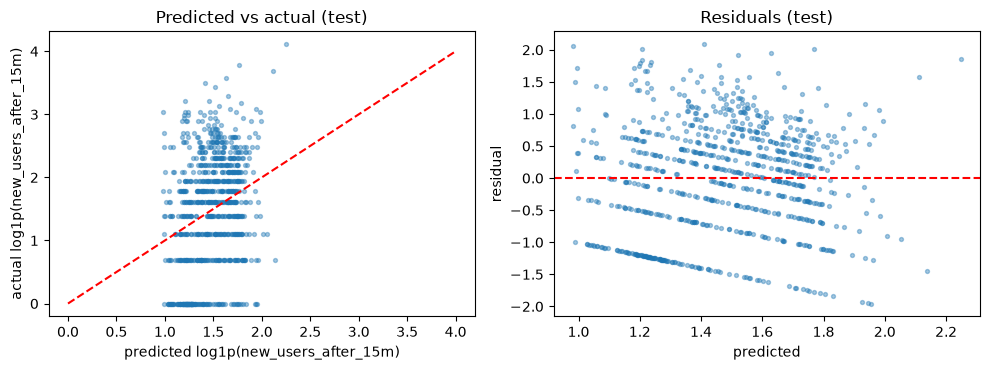

In [12]:
names = {"author_followers": "log followers", "author_verified": "verified", f"replies_{WINDOW}m": f"log replies in {WINDOW} min"}


def coefs_of(m, features):
    counts = [f for f in features if f != "author_verified"]
    order = counts + (["author_verified"] if "author_verified" in features else [])
    return pd.Series(m.named_steps["ridge"].coef_, index=[names[f] for f in order])


coefs = pd.DataFrame({"velocity": coefs_of(velocity_model, VELOCITY), "author-only": coefs_of(author_model, AUTHOR)}).round(4)
print(coefs.to_string())

p_test = velocity_model.predict(test[VELOCITY])
y_test = np.log1p(test[NEW])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(p_test, y_test, s=8, alpha=0.4)
ax[0].plot([0, 4], [0, 4], color="red", linestyle="--")
ax[0].set_xlabel(f"predicted log1p({NEW})"); ax[0].set_ylabel(f"actual log1p({NEW})")
ax[0].set_title("Predicted vs actual (test)")
ax[1].scatter(p_test, y_test - p_test, s=8, alpha=0.4)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("residual"); ax[1].set_title("Residuals (test)")
plt.tight_layout(); plt.show()

## 10. From a number to a spread-risk level

The dashboard shows Low, Moderate or High. PHEME cascades are small, so fixed thresholds such as 1,000 users do not fit. For each mode we compute the **estimated total reach** on the training set and cut it into three equal groups (tertiles):

- live post: `observed_users_15m + predicted new_users_after_15m`,
- new claim: predicted `unique_users` from the author-only model.

On the test set we check how many users the cascades in each level really reached.

In [13]:
def reach_live(m, d):
    return d[OBS].to_numpy() + np.expm1(m.predict(d[VELOCITY]))


def reach_new_claim(m, d):
    return np.expm1(m.predict(d[AUTHOR]))


def tertiles(reach):
    return tuple(float(x) for x in np.quantile(reach, [1 / 3, 2 / 3]))


def risk_level(reach, cuts):
    low, high = cuts
    return np.where(reach < low, "Low", np.where(reach < high, "Moderate", "High"))


def risk_table(reach, cuts, d):
    level = pd.Series(risk_level(reach, cuts), index=d.index, name="risk")
    return (d.groupby(level)[TOTAL].agg(cascades="size", mean_users="mean", median_users="median")
            .reindex(["Low", "Moderate", "High"]).round(1))


cuts_live = tertiles(reach_live(velocity_model, train))
cuts_new = tertiles(reach_new_claim(author_model, train))
risk_live = risk_table(reach_live(velocity_model, test), cuts_live, test)
risk_new = risk_table(reach_new_claim(author_model, test), cuts_new, test)
print(f"live post: cut points {cuts_live[0]:.1f} and {cuts_live[1]:.1f} estimated users")
print(risk_live.to_string())
print()
print(f"new claim (author-only): cut points {cuts_new[0]:.1f} and {cuts_new[1]:.1f} estimated users")
print(risk_new.to_string())

live post: cut points 5.7 and 10.6 estimated users
          cascades  mean_users  median_users
risk                                        
Low            273         5.6           4.0
Moderate       262        10.4           9.0
High           270        17.9          17.0

new claim (author-only): cut points 7.6 and 9.5 estimated users
          cascades  mean_users  median_users
risk                                        
Low            267         9.8           8.0
Moderate       249        11.6          10.0
High           289        12.3          12.0


## 11. Save the models and the report

The `.joblib` file is a dictionary with both pipelines and the recipe for the total reach:

```python
art = joblib.load("backend/models/spread_regressor.joblib")
# live post (15 minutes after posting)
X = pd.DataFrame({"author_followers": [450000], "author_verified": [1], "replies_15m": [6]})
reach = observed_users_15m + float(np.expm1(art["model"].predict(X))[0])
# new claim (not posted yet)
reach = float(np.expm1(art["model_author_only"].predict(X[art["features_author_only"]]))[0])
```

In [14]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer):
        return int(o)
    return o


versions = {"sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__}

artifact = {
    "model": velocity_model,
    "features": VELOCITY,
    "target": f"log1p({NEW}): users whose first tweet in the cascade comes after minute {WINDOW}",
    "model_author_only": author_model,
    "features_author_only": AUTHOR,
    "target_author_only": f"log1p({TOTAL}): all users in the finished cascade",
    "velocity_window_min": WINDOW,
    "reach_formula": {
        "live_post": f"{OBS} + expm1(model.predict(X[features]))  ({OBS} = distinct users seen by minute {WINDOW}, author included)",
        "new_claim": "expm1(model_author_only.predict(X[features_author_only]))",
    },
    "alpha": {"velocity": alpha_velocity, "author_only": alpha_author},
    "risk_cut_points_users": {"live_post": {"low_below": cuts_live[0], "high_from": cuts_live[1]},
                              "new_claim": {"low_below": cuts_new[0], "high_from": cuts_new[1]}},
    "risk_rule": "Low if reach < low_below, High if reach >= high_from, else Moderate (tertiles of training reach)",
    "trained_on": "split == 'train'",
    "versions": versions,
}
joblib.dump(artifact, MODELS / "spread_regressor.joblib")

report = {
    "data": {"cascades": len(df), "tweets": len(tweets), "train": len(train), "val": len(val), "test": len(test),
             "excluded_label": len(extra), "excluded_dup": int((df["split"] == "excluded_dup").sum())},
    "velocity_window_min": WINDOW,
    "targets": {"velocity": artifact["target"], "author_only": artifact["target_author_only"]},
    "reach_formula": artifact["reach_formula"],
    "scoring_note": f"velocity model scored on {NEW} only; MAE on total reach equals MAE on {NEW}; "
                    "R2 on total reach is inflated by the observed part and not reported",
    "features": {"velocity": VELOCITY, "author_only": AUTHOR},
    "alpha": artifact["alpha"],
    "visible_at_cutoff": visible.to_dict(orient="records"),
    "spearman_vs_targets": corr.to_dict(),
    "results": results.to_dict(orient="index"),
    "test_mae_total_equals_new": {"mae_total": mae_total, f"mae_{NEW}": float(mae_new)},
    "window_scan_val": window_table.to_dict(orient="records"),
    "experiment_b": exp_b.to_dict(orient="index"),
    "leave_one_event_out": loeo.to_dict(orient="records"),
    "coefficients": coefs.to_dict(),
    "risk_cut_points_users": artifact["risk_cut_points_users"],
    "risk_table_test": {"live_post": risk_live.to_dict(orient="index"), "new_claim": risk_new.to_dict(orient="index")},
    "versions": versions,
    "seed": SEED,
}
with open(REPORTS / "spread_metrics.json", "w", encoding="utf-8") as f:
    json.dump(clean(report), f, indent=2)
print("saved:", MODELS / "spread_regressor.joblib")
print("saved:", REPORTS / "spread_metrics.json")

saved: /Users/phaman/Documents/COS30048 - Inno/inno/backend/models/spread_regressor.joblib
saved: /Users/phaman/Documents/COS30048 - Inno/inno/backend/reports/spread_metrics.json


In [15]:
# Reload test: this is what the backend will do in each mode
art = joblib.load(MODELS / "spread_regressor.joblib")
sample = pd.DataFrame({"author_followers": [450_000, 800, 25_000_000],
                       "author_verified": [1, 0, 1],
                       f"replies_{WINDOW}m": [6, 0, 2],
                       OBS: [5, 1, 3]})
cut_live = art["risk_cut_points_users"]["live_post"]
cut_new = art["risk_cut_points_users"]["new_claim"]
live = sample[OBS] + np.expm1(art["model"].predict(sample[art["features"]]))
new = np.expm1(art["model_author_only"].predict(sample[art["features_author_only"]]))
print(pd.DataFrame({
    "followers": sample["author_followers"], "verified": sample["author_verified"],
    f"replies_{WINDOW}m": sample[f"replies_{WINDOW}m"], OBS: sample[OBS],
    "reach (live post)": live.round(1),
    "risk (live post)": risk_level(live.to_numpy(), (cut_live["low_below"], cut_live["high_from"])),
    "reach (new claim)": new.round(1),
    "risk (new claim)": risk_level(new, (cut_new["low_below"], cut_new["high_from"])),
}).to_string(index=False))

 followers  verified  replies_15m  observed_users_15m  reach (live post) risk (live post)  reach (new claim) risk (new claim)
    450000         1            6                   5                8.6         Moderate               10.1             High
       800         0            0                   1                3.4              Low                5.9              Low
  25000000         1            2                   3                5.4              Low               13.6             High


### Numbers quoted in the Discussion

Every number in the Discussion below is printed here or in an earlier cell, so it cannot go stale on a re-run.

In [16]:
v_test, v_base = results.loc["velocity: model test"], results.loc["velocity: baseline test"]
a_test, a_base = results.loc["author-only: model test"], results.loc["author-only: baseline test"]
vis = visible.set_index("cutoff_min")
rho_observed = rank_corr(test[TOTAL], test[OBS].to_numpy())
rho_live = rank_corr(test[TOTAL], reach_live(velocity_model, test))
facts = {
    f"test Spearman with unique_users: {OBS} alone / observed + predicted": [round(rho_observed, 3), round(rho_live, 3)],
    "earlier version (30-min replies, total target): test R2": 0.629,
    f"velocity test on {NEW}: R2 / MAE / Spearman": [v_test["r2_log"], v_test["mae_users"], v_test["spearman"]],
    f"mean baseline test on {NEW}: R2 / MAE": [v_base["r2_log"], v_base["mae_users"]],
    "author-only test on unique_users: R2 / MAE / Spearman": [a_test["r2_log"], a_test["mae_users"], a_test["spearman"]],
    "mean baseline test on unique_users: R2 / MAE": [a_base["r2_log"], a_base["mae_users"]],
    f"share of users already seen at {WINDOW} min / cascades with no new users after": [vis.loc[WINDOW, "share_of_users_already_seen"],
                                                                                        vis.loc[WINDOW, "cascades_with_no_new_users"]],
    f"median new users after {WINDOW} min (train+val+test)": float(pool[NEW].median()),
    "unseen events mean R2: velocity / its baseline / author-only / its baseline":
        [round(float(loeo[c].mean()), 3) for c in ["velocity R2", "velocity baseline R2", "author-only R2", "author baseline R2"]],
    "unseen events where velocity R2 > 0": int((loeo["velocity R2"] > 0).sum()),
    "velocity validation R2 by cutoff 5/15/30/60": window_table["val_r2_log"].tolist(),
}
for k, v in facts.items():
    print(f"{k}: {[round(float(x), 3) for x in v] if isinstance(v, list) else v}")

test Spearman with unique_users: observed_users_15m alone / observed + predicted: [0.736, 0.741]
earlier version (30-min replies, total target): test R2: 0.629
velocity test on new_users_after_15m: R2 / MAE / Spearman: [0.082, 3.855, 0.267]
mean baseline test on new_users_after_15m: R2 / MAE: [-0.002, 3.988]
author-only test on unique_users: R2 / MAE / Spearman: [0.056, 6.075, 0.197]
mean baseline test on unique_users: R2 / MAE: [-0.0, 6.268]
share of users already seen at 15 min / cascades with no new users after: [0.517, 0.163]
median new users after 15 min (train+val+test): 4.0
unseen events mean R2: velocity / its baseline / author-only / its baseline: [-0.056, -0.116, -0.116, -0.135]
unseen events where velocity R2 > 0: 0
velocity validation R2 by cutoff 5/15/30/60: [0.105, 0.068, 0.072, 0.047]


## 12. Discussion

**1. The earlier result was inflated, and we corrected it.** An earlier version of this notebook predicted the total number of users from the replies in the first 30 minutes and reported a test R2 of 0.629. The users who replied in those 30 minutes are part of that total, so the model was mostly counting users it had already seen. The team found this double counting and changed the setup: the velocity model now predicts only the users who join **after** minute 15 (`new_users_after_15m`), the users seen by minute 15 are added as an observed count, and only the part after the cutoff is scored.

**2. In PHEME, growth after the cutoff is hard to predict.** On the test set the velocity model reaches R2 = 0.082 on the log scale for the users after minute 15, against -0.002 for the mean baseline. Its average error is 3.86 users against 3.99, and its rank correlation is 0.267. That is a real but small improvement. By minute 15, 51.7% of all users have already arrived and 16.3% of cascades get no new user at all; the median cascade still gains 4 users afterwards. The number of early replies says little about how many more people will join. Followers and the verified badge add nothing once early replies are known (standardised coefficients -0.05 and -0.09, against +0.25 for log replies in 15 minutes).

**3. The cutoff does not change this picture.** On validation the R2 for the part after the cutoff is 0.105 at 5 minutes, 0.068 at 15, 0.072 at 30 and 0.047 at 60. No cutoff makes later growth predictable. A later cutoff makes the average error smaller only because less growth is left (Section 6). The team kept 15 minutes as an early warning point, chosen before looking at the test set.

**4. Events the model has never seen.** When a whole event is held out, the velocity model is negative on all five events (mean R2 -0.056) and the mean baseline is lower (-0.116). Its average error is close to the baseline in each event. The improvement on the random split does not carry over to a new event in a useful way.

**5. A new claim only has the author-only model, and it is weak.** Before a claim is posted nothing can be observed, so only followers and verified are available. That model reaches R2 = 0.056 on the total number of users, against 0.000 for the baseline. Its average error is 6.08 users against 6.27, its rank correlation 0.197, and on unseen events its mean R2 is -0.116 (baseline -0.135). Its risk levels hardly separate on the test set: median 8, 10 and 12 users for Low, Moderate and High.

**6. Live-post risk levels come mostly from what is already seen.** For a live post the estimated reach is `observed_users_15m + predicted new users`. Its risk levels separate well on test (median 4, 9 and 17 users), but almost all of that comes from the observed part. The users seen by minute 15 alone rank the final reach with a Spearman correlation of 0.736, and adding the model's prediction only raises it to 0.741. The level is therefore a useful summary of how a post has started, not a forecast of how far it will go.

**7. What the dashboard should say.** The spread risk should be shown only as a rough estimate. For a new claim it says little beyond "this author has a bigger or smaller audience". For a live post it mostly reflects the activity of the first 15 minutes. The page should not present `expected_reach` as a reliable prediction, and it should describe it as "unique users in the conversation".

**8. Limitations and what the backend needs.** PHEME holds replies, not retweets, so "reach" means the accounts that took part in the conversation, not everyone who saw the post. The cascades are small (median 10 users) and come from a few events in 2014-2015. For a live post, `POST /api/predict` needs two optional inputs, `replies_15m` and `observed_users_15m`, and then uses `model` with the `live_post` cut points. Without them it uses `model_author_only` with the `new_claim` cut points. `expected_reach` should be rounded to an integer. This is backend work for WBS 4.2.